```{eval-rst}
:download:`Download notebook <backend.ipynb>`
```

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


# Enable Niagara beneath existing Caustics calls

Construct the model with the usual Caustics imports, then enable Niagara on
the simulator instance:

This example builds a stock 64 x 64 Caustics `LensSource` with SIE mass, shear, Sersic source/lens light and a Gaussian PSF. Native calls compute the reference images and all 21 gradients before activation; the results are kept on CPU for comparison. The cells use `cuda:0` and `cuda:1` when both are visible. A one-device fallback checks that configuration only.

![Lensing and source placement](../_static/guide/multi_gpu_flow.svg)

In [1]:
%matplotlib inline
import caskade as ck
import caustics
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import PowerNorm

import niagara as ng
from examples.niagara_examples.caustics import image_problem

visible_devices = torch.cuda.device_count()
home = torch.device("cuda:0" if visible_devices else "cpu")
source_home = torch.device("cuda:1" if visible_devices >= 2 else home)
problem = image_problem(64, device=home, dtype=torch.float64)
sim, params = problem.model, problem.truth.detach()
native_class = type(sim)
parameter_ids = tuple(id(p) for p in sim.dynamic_params)
reference = sim(params).detach().cpu()
source_reference = sim(params, lens_light=False).detach().cpu()
q_native = params.clone().requires_grad_()
native_loss = sim(q_native).square().sum()
native_gradient = torch.autograd.grad(native_loss, q_native)[0].detach().cpu()
del q_native, native_loss

print(
    {
        "niagara": ng.__version__,
        "caskade": ck.__version__,
        "caustics": caustics.__version__,
        "torch": str(torch.__version__),
    }
)
print("Visible CUDA devices:", visible_devices)
if visible_devices < 2:
    print("Two-GPU placement is unavailable; this run uses one available device.")
print(
    "Image shape:",
    tuple(reference.shape),
    "parameters:",
    len(problem.names),
    "dtype:",
    params.dtype,
)

engine = ng.enable(sim, default=home, modules={"source": source_home}, example=params)
image = sim(params)
assert image.device == home and sim.source.Re.device == source_home
torch.testing.assert_close(image.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Output home:", image.device, "source home:", sim.source.Re.device)
print("Selected backend:", engine.programs[0].backend)

{'niagara': '0.7.0', 'caskade': '1.1.5', 'caustics': '1.7.1', 'torch': '2.12.0+cu126'}
Visible CUDA devices: 2
Image shape: (64, 64) parameters: 21 dtype: torch.float64


Output home: cuda:0 source home: cuda:1
Selected backend: cuda_graph


The native and enabled calls render the same noiseless image. Both panels use one intensity scale and a square-root color stretch, which changes only the display contrast.

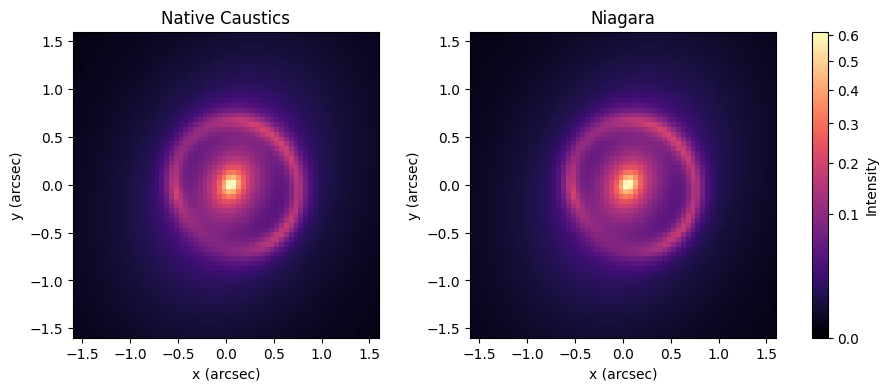

Image maximum absolute difference: 3.885780586188048e-16


In [2]:
enabled_image = image.detach().cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
norm = PowerNorm(gamma=0.5, vmin=0, vmax=float(reference.max()))
for ax, data, title in zip(
    axes, (reference.numpy(), enabled_image), ("Native Caustics", "Niagara")
):
    artist = ax.imshow(data, origin="lower", extent=(-1.6, 1.6, -1.6, 1.6), cmap="magma", norm=norm)
    ax.set(title=title, xlabel="x (arcsec)", ylabel="y (arcsec)")
fig.colorbar(artist, ax=axes, label="Intensity")
plt.show()
print("Image maximum absolute difference:", float((image.detach().cpu() - reference).abs().max()))

For one GPU, omit `modules`. `example=params` prepares the usual packed call at
activation; without an example the first call prepares lazily. Inputs already
on the default GPU avoid repeated host-to-device transfer.

Niagara uses temporary subclasses for the enabled instances. Caskade/Caustics
remain installed dependencies, with their global imports and files unchanged.
CUDA's process default also stays unchanged.

## Call specializations

Positional and keyword packed parameters, input trees, tensor metadata, fixed
scalar flags, requires-grad settings and execution modes can produce separate
programs. For example, prepare both forms before a fixed loop:

In [3]:
sim(params)
sim(params=params)
source_image = sim(params, lens_light=False)
torch.testing.assert_close(source_image.detach().cpu(), source_reference, atol=1e-10, rtol=1e-9)
with engine.session():
    first = sim(params)
    second = sim(params=params)
    torch.testing.assert_close(first, second)
print("Prepared call forms:", len(engine.programs))
print("Backends:", [program.backend for program in engine.programs])
print("Source-only shape/device:", tuple(source_image.shape), source_image.device)

Prepared call forms: 3
Backends: ['cuda_graph', 'cuda_graph', 'cuda_graph']
Source-only shape/device: (64, 64) cuda:0


Every call checks input and execution-mode guards. A session checks model
state around its block, saving that work on each iteration. Keep model state
and call signatures fixed inside the block. The default limit is eight
programs; increase `max_programs` when a workload needs more.

Use `engine.clear()` before recapturing intentional static-configuration
changes. Reassigning device ownership or changing the model graph requires
disabling and re-enabling; clearing programs alone does not validate a new DAG.

## Native contexts and ordinary gradients

Calls within an active Caskade context use routed native parameters and
overrides, rather than a program captured outside that context. Ordinary
autograd gets a requires-grad specialization:

In [4]:
q = params.clone().requires_grad_()
loss = sim(q).square().sum()
gradient = torch.autograd.grad(loss, q)[0]
assert gradient.device == home and gradient.numel() == 21
actual_gradient = gradient.detach().cpu()
torch.testing.assert_close(actual_gradient, native_gradient, atol=1e-9, rtol=1e-8)
absolute = (actual_gradient - native_gradient).abs()
worst = int(absolute.argmax())
print("All 21 gradient components agree.")
print("Maximum absolute difference:", float(absolute.max()), "at", problem.names[worst])
print("Reference at that component:", float(native_gradient[worst]))
print(f"{'Parameter':20s} {'Native':>13s} {'Niagara':>13s} {'Absolute error':>15s}")
for name, native, actual, error in zip(
    problem.names, native_gradient.tolist(), actual_gradient.tolist(), absolute.tolist()
):
    print(f"{name:20s} {native:13.5e} {actual:13.5e} {error:15.5e}")

with ck.ActiveContext(sim):
    engine.placement.fill_params(sim, params)
    context_image = sim()
torch.testing.assert_close(context_image.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Active-context image agrees; native routed parameter filling is preserved.")

All 21 gradient components agree.
Maximum absolute difference: 1.554312234475219e-14 at shear.gamma_1
Reference at that component: -2.2773892452733584
Parameter                   Native       Niagara  Absolute error
mass.x0                3.61956e+01   3.61956e+01     1.42109e-14
mass.y0               -1.48902e+01  -1.48902e+01     7.10543e-15
mass.q                -4.00490e-01  -4.00490e-01     8.10463e-15
mass.phi              -4.17631e-01  -4.17631e-01     5.55112e-16
mass.Rein             -4.95764e-01  -4.95764e-01     1.01030e-14
shear.gamma_1         -2.27739e+00  -2.27739e+00     1.55431e-14
shear.gamma_2          5.67117e+00   5.67117e+00     5.32907e-15
source.x0             -3.60853e+01  -3.60853e+01     1.42109e-14
source.y0              1.68906e+01   1.68906e+01     1.42109e-14
source.q               4.96903e+00   4.96903e+00     8.88178e-16
source.phi            -2.14205e-01  -2.14205e-01     0.00000e+00
source.n               3.67621e+00   3.67621e+00     0.00000e+00
sour

For an already active multi-device context, `engine.placement.fill_params` stages the packed parameter views on their declared homes before the routed call.

For functional derivatives and batching, use the pure-graph APIs described in
[derivatives](derivatives.ipynb). Compose transformations before final compilation.
Wrapping enabled dispatch inside an arbitrary outer compiler/capture remains
outside the supported composition interface.

## Other entry points and dynamic Python

For method-based simulators, select class methods explicitly:

In [5]:
lens = caustics.SIE(
    caustics.FlatLambdaCDM(name="method_cosmology"),
    z_l=0.5,
    z_s=1.5,
    x0=0.0,
    y0=0.0,
    q=0.8,
    phi=0.2,
    Rein=0.7,
    name="method_lens",
)
lens.to(device=home, dtype=torch.float64)
x = torch.linspace(-1.0, 1.0, 7, device=home, dtype=torch.float64)
y = x.roll(1)
expected_rays = tuple(value.detach().cpu() for value in lens.raytrace(x, y))
expected_potential = lens.potential(x, y).detach().cpu()
with ng.enable(lens, default=home, methods=("raytrace", "potential")) as method_engine:
    rays = lens.raytrace(x, y)
    potential = lens.potential(x, y)
    for actual, expected in zip(rays, expected_rays):
        torch.testing.assert_close(actual.detach().cpu(), expected)
    torch.testing.assert_close(potential.detach().cpu(), expected_potential)
    print("Raytrace shapes:", [tuple(value.shape) for value in rays])
    print("Potential shape/device:", tuple(potential.shape), potential.device)
    print("Selected-method programs:", len(method_engine.programs))

Raytrace shapes: [(7,), (7,)]
Potential shape/device: (7,) cuda:0
Selected-method programs: 2


Methods not selected for compilation still use the placement's ordinary
forward-boundary routing. `compile=False` enables routing without fixed-program
capture, which is useful for dynamic Python that cannot be specialized safely.
Compiler failures raise errors, so eager execution cannot be mistaken for
compiled work.

## Disable and restore

In [6]:
ng.disable(sim)
restored = sim(params)
assert type(sim) is native_class
assert tuple(id(p) for p in sim.dynamic_params) == parameter_ids
assert sim.source.Re.device == home
torch.testing.assert_close(restored.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Native class restored:", type(sim).__name__)
print("Source home after disable:", sim.source.Re.device)
print("A second disable is a no-op:", not ng.disable(sim))

Native class restored: LensSource
Source home after disable: cuda:0
A second disable is a no-op: True


Disable restores original dispatch classes and co-locates simulator tensors on
the plan's default home. It preserves parameter identity and ties. Separately
held inputs/results remain where the caller placed them. Disable is idempotent
and is rejected while a model or fixed session is active.

The backend supports one caller at a time. Give simultaneous callers separate
simulators or replicas; compiled programs share fixed buffers without a
concurrency lock. Disable before serialization when native classes are required.